In [1]:
import nibabel as nib
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from losses import jacobian_determinant_torch
import re
import os

In [2]:
df = pd.read_csv("template_csvs/ADNI1_Complete_DataSplits.csv")
subject = "002_S_0295"
visit = "m06"
# find the row in the dataframe that matches the subject and visit
image_path = df.loc[(df['Subject'] == subject) & (df['Visit'] == visit), 'File_Path'].values[0]
svf_path = f"/scratch/anirudhkaushik/svf_outputs/{subject}_sc_{visit}.pt"

image = nib.load(image_path)
image_data = image.get_fdata()

svf = torch.load(svf_path)
svf = svf.unsqueeze(0)
print(image_data.shape, svf.shape)

img_id_re_pattern = r"I\d+"
img_id = re.search(img_id_re_pattern, image_path).group(0)

# get mask image by image_id
mask_dir = "/scratch/anirudhkaushik/ADNI_Resized_Registered_brain_masks/"
#find the mask file that matches the image_id
all_mask_files = os.listdir(mask_dir)
mask_file = [f for f in all_mask_files if re.search(img_id_re_pattern, f) is not None][0]
mask_path = os.path.join(mask_dir, mask_file)
mask = nib.load(mask_path)
mask_data = mask.get_fdata()

2025-05-26 09:39:20.011179: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


(128, 128, 128) torch.Size([1, 3, 128, 128, 128])


-0.7619376182556152 1.39235258102417


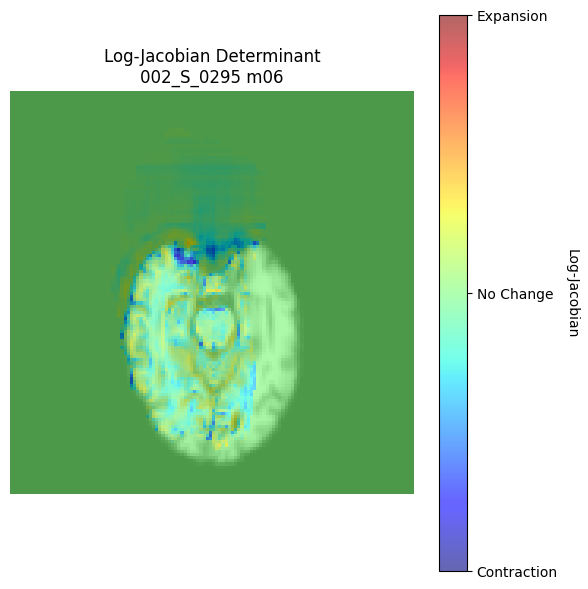

In [3]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import torch.nn.functional as F
import torch

# === Compute Jacobian ===
jac_det = jacobian_determinant_torch(svf)  # assumed shape [1, 1, 127, 127, 127]
jac_det = jac_det.squeeze().cpu().numpy()

# === Compute Log-Jacobian ===
log_jac_det = np.log(jac_det + 1e-6)  # avoid log(0)

# === Pad to match image resolution (128³) ===
log_jac_det_tensor = torch.tensor(log_jac_det).unsqueeze(0).unsqueeze(0)  # [1, 1, 127, 127, 127]
log_jac_det_padded = F.pad(log_jac_det_tensor, (0, 1, 0, 1, 0, 1), mode='replicate')
log_jac_det = log_jac_det_padded.squeeze().numpy()  # [128, 128, 128]

# === Apply brain mask ===
log_jac_det = log_jac_det * mask_data.astype(bool)

# === Visualization ===
slice_idx = 64  # axial slice
vmin = log_jac_det.min()/2    # contraction
vmax =  log_jac_det.max()/2    # expansion

print(vmin, vmax)

plt.figure(figsize=(6, 6))
plt.imshow(image_data[:, :, slice_idx], cmap='gray', interpolation='none')
plt.imshow(log_jac_det[:, :, slice_idx],
           cmap='jet',                # red-blue diverging colormap
           norm=mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax),
           alpha=0.6,                     # transparency for overlay
           interpolation='none')
cbar = plt.colorbar()
cbar.set_label("Log-Jacobian", rotation=270, labelpad=15)
cbar.set_ticks([vmin, 0, vmax])
cbar.set_ticklabels(['Contraction', 'No Change', 'Expansion'])

plt.title(f"Log-Jacobian Determinant\n{subject} {visit}")
plt.axis('off')
plt.tight_layout()
plt.show()


/scratch/anirudhkaushik/ADNI_Resized_Registered/ADNI_137_S_0722_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948089_S46588_I99131_padded_transposed_padded_transposed.nii.gz
ADNI_137_S_0722_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948089_S46588_I99131_padded_transposed_padded_transposed_aparc.DKTatlas+aseg.deep_resized_IPL_padded.nii.gz


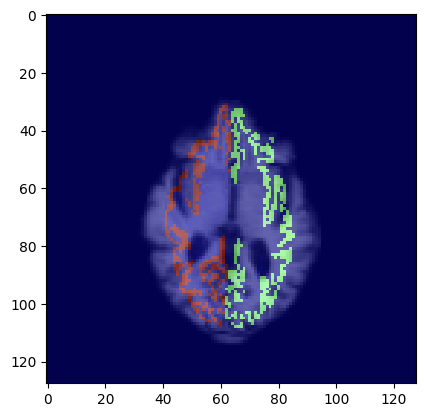

In [16]:
visit = "m18"
image_path = df.loc[(df['fold_1'] == 'test') & (df['Visit'] == visit), 'File_Path'].values[1]
print(image_path)
image = nib.load(image_path)
image_data = image.get_fdata()
# get mask 
image_id = "I99131"
mask_dir = "/scratch/anirudhkaushik/ADNI_Resized_Registered_segs/"
#find the mask file that matches the image_id
all_mask_files = os.listdir(mask_dir)
mask_file = [f for f in all_mask_files if image_id in f][0]
print(mask_file)
mask_path = os.path.join(mask_dir, mask_file)
mask = nib.load(mask_path)
mask_data = mask.get_fdata()
plt.imshow(image_data[:, :, 64], cmap='gray', interpolation='none')
plt.imshow(mask_data[:, :, 64], cmap='jet',                # red-blue diverging colormap
           alpha=0.6,                     # transparency for overlay
           interpolation='none')
plt.show()

In [2]:
all_noder_files = os.listdir("/scratch/anirudhkaushik/NODER_result_1")
target_file = [f for f in all_noder_files if "S44863_I92696" in f][0]
print(target_file)

ADNI_114_S_1106_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948688_S44863_I92696_padded_transposed_padded_transposed.nii.gz


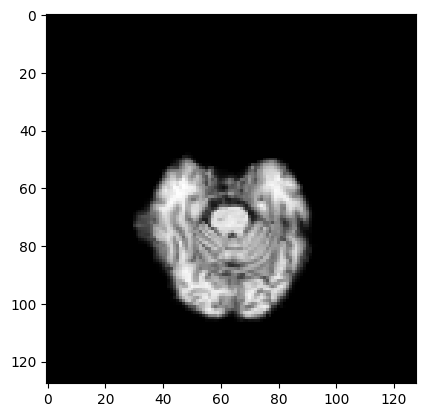

In [3]:
img = nib.load(f"/scratch/anirudhkaushik/NODER_result_1/{target_file}")
img_data = img.get_fdata()
plt.imshow(img_data[:, :, 64], cmap='gray', interpolation='none')

ADNI_114_S_1106_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948688_S44863_I92696_padded_transposed_padded_transposed.nii.gz


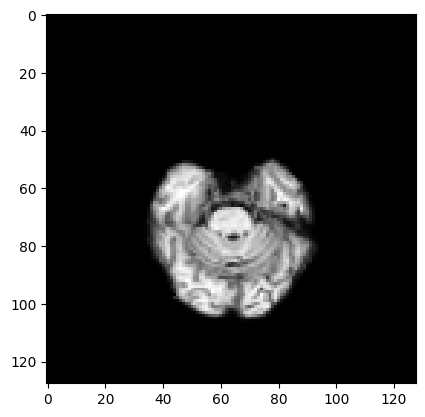

In [16]:
all_noder_files = os.listdir("/scratch/anirudhkaushik/NODER_result_1")
target_file = [f for f in all_noder_files if "S44863_I92696" in f][0]
print(target_file)
img = nib.load(f"/scratch/anirudhkaushik/NODER_result_1/{target_file}")
img_data = img.get_fdata()
plt.imshow(img_data[:, :, 64], cmap='gray', interpolation='none')

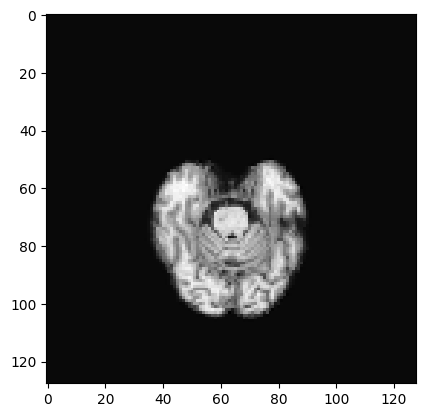

In [14]:
all_noder_files = os.listdir("/scratch/anirudhkaushik/SYNBADD_Qualitative_1/SYNBADD_128_6_5e-05_0.0_2025-04-16_04-59-48_ADNI_all_longitudinal_FinalVAETransformer_Vanilla_Fold1/")
target_file = [f for f in all_noder_files if "S44863_I92696" in f][1]
img = nib.load(f"/scratch/anirudhkaushik/SYNBADD_Qualitative_1/SYNBADD_128_6_5e-05_0.0_2025-04-16_04-59-48_ADNI_all_longitudinal_FinalVAETransformer_Vanilla_Fold1/{target_file}")
img_data = img.get_fdata()[0]
# print(img_data.shape)
plt.imshow(img_data[:, :, 64], cmap='gray', interpolation='none')

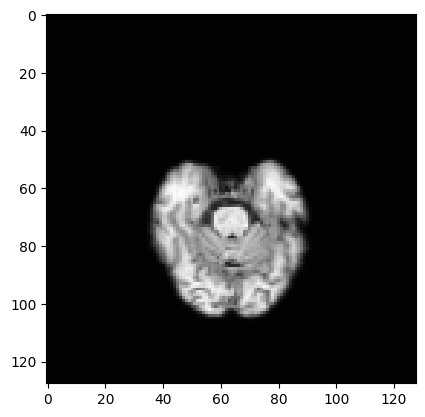

In [4]:
all_target_files= os.listdir("/scratch/anirudhkaushik/ADNI_Resized_Registered/")
target_file = [f for f in all_target_files if "S44863_I92696" in f][0]
img = nib.load(f"/scratch/anirudhkaushik/ADNI_Resized_Registered/{target_file}")
img_data = img.get_fdata()
# print(img_data.shape)
plt.imshow(img_data[:, :, 64], cmap='gray', interpolation='none')

In [ ]:
import ants
target_img = "/scratch/anirudhkaushik/ADNI_Resized_Registered/ADNI_941_S_1194_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948997_S38206_I75141_padded_transposed_padded_transposed.nii.gz"
moving_img = "/scratch/anirudhkaushik/interpolated-ADNI_941_S_1194_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948997_S38206_I75141_padded_transposed_padded_transposed.nii.gz"

target = ants.image_read(target_img)
moving = ants.image_read(moving_img)
# Perform registration
registration = ants.registration(fixed=target, moving=moving, type_of_transform='Affine')
# Apply the transformation to the moving image
warped_moving = ants.apply_transforms(fixed=target, moving=moving, transformlist=registration['fwdtransforms'])




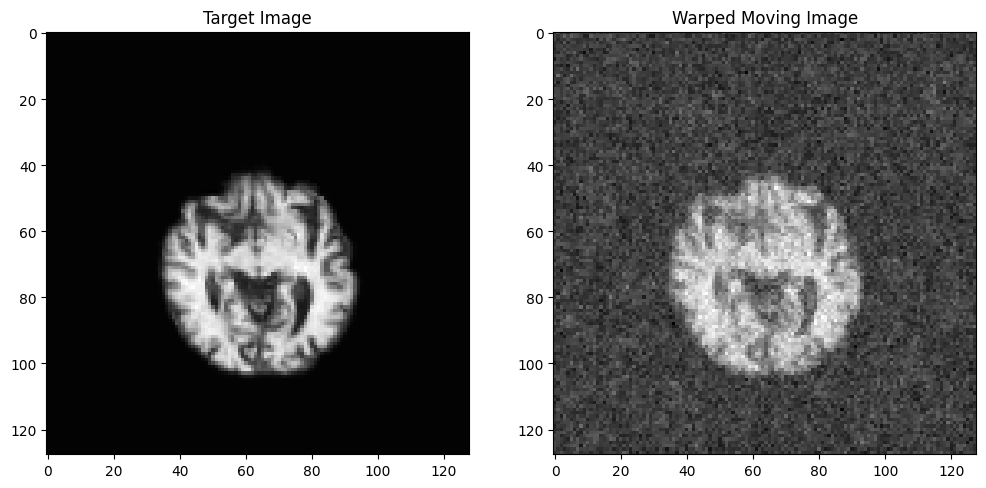

In [11]:
# display
import nibabel as nib

warped_moving = nib.load(moving_img).get_fdata()  # Transpose to match the target orientation
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(target.numpy()[:, :, 64], cmap='gray', interpolation='none')
plt.title('Target Image')
plt.subplot(1, 2, 2)
plt.imshow(warped_moving[:, :, 64], cmap='gray', interpolation='none')
plt.title('Warped Moving Image')
plt.show()

In [4]:
import numpy as np
target_numpy = target.numpy()
warped_moving_numpy = warped_moving.numpy()

# calculate ssim and psnr
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr


# choose image where it is > 0
target_img_single = np.where(target_numpy > 0, target_numpy, 0)
generated_img_single = np.where(warped_moving_numpy > 0, warped_moving_numpy, 0)

# normalize
target_img_single = (target_img_single - target_img_single.min()) / (target_img_single.max() - target_img_single.min()) * 255
generated_img_single = (generated_img_single - generated_img_single.min()) / (generated_img_single.max() - generated_img_single.min()) * 255

# convert to uint8
target_img_single = target_img_single.astype(np.uint8)
generated_img_single = generated_img_single.astype(np.uint8)

# Calculate PSNR and SSIM
psnr_value_t = psnr(generated_img_single, target_img_single)
ssim_value_t = ssim(generated_img_single, target_img_single, multichannel=False)

print(f"PSNR: {psnr_value_t:.2f} dB")
print(f"SSIM: {ssim_value_t:.4f}")

PSNR: 10.39 dB
SSIM: 0.0373
